# 09 Extreme-storm check on the full cohort

Notebook 04 found, on two rocket bodies, that MSIS over-predicts the decay in days 0..+3
after the May and Oct 2024 storms, and that in May this vanished with 3-day smoothing (TLE
blur). Here the same question on the **250 passive main-cohort objects** of
`data/processed/analysis_table.parquet` (passive only, `schema.main_sample`).

Steps (`src/extreme_check.py`, functions in `src/physics.py`):
1. Notebook-04 checks at cohort scale: baseline-relative residual (days 0..+3 minus days
   -10..-3) for all 20 storms, MSIS 2.1 and NRLMSISE-00; the prediction smoothed over 1, 2, 3
   days; lag cross-correlation. SE over objects for one storm, over storms when pooling.
2. Blur-free outcome `physics.calm_to_calm`: semi-major axis lost from the last calm day in
   days -10..-3 to the first calm day after `recovery_end` (calm = every 3-hour ap < 27),
   observed vs MSIS 2.1 over the same intervals. Blur moves decay in time but cannot change
   the total, since da/dt * dt sums to a(end) - a(start). The intervals A4 left out because
   they bridge `main_onset` are filled back in from the TLEs (`physics.fill_onset_gaps`).
3. The same split by altitude band.
4. Verdict with the PLAN.md rules: "real model overshoot" only if the over-prediction
   survives smoothing **and** shows in the calm-to-calm loss.

Note: in the storm catalog Oct 2024 (-333 nT) is **severe**, not extreme; the two severe storms
are Oct 2024 and Dec 31 2024 (-212 nT). "May + Oct" below means the two deepest storms.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import extreme_check as ec
from src import physics
from src.plots import (plot_storm_change_means, plot_extreme_smoothing, plot_lag_check,
                       plot_calm_cumulative, plot_calm_summary)

RESULTS = ROOT / "results"
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.3g}")

inputs = ec.load_inputs()
storms = inputs[1]
out = ec.run(inputs)          # ~2 min; onset-gap drivers cached in data/processed/
names, pair = out["names"], out["pair"]
print(f"{out['n_objects']} passive objects; key storms: {names}; verdict pair: {[names[s] for s in pair]}")

smoothing / baseline checks ...


lag check ...


calm-to-calm loss ...


250 passive objects; key storms: {4: 'May 2024 (extreme)', 11: 'Oct 2024 (severe)', 13: 'Dec 2024 (severe)'}; verdict pair: ['May 2024 (extreme)', 'Oct 2024 (severe)']


## 1. Baseline-relative residual, all 20 storms

Per storm and object: time-weighted mean residual over days 0..+3 minus days -10..-3
(`physics.storm_baseline_residual`, Hampel outliers out). Objects are averaged within a storm;
pooled = mean over storms, SE across storms (storm = cluster, t interval).

In [2]:
out["pooled"]

mean   se  ci_lo  ci_hi  storms  positive
outcome               sample                                                           
MSIS 2.1              all storms             0.823 3.16  -5.78   7.43      20        10
                      without May/Oct 2024   -1.83 2.76  -7.64   3.98      18         8
NRLMSISE-00           all storms              1.29 3.15   -5.3   7.88      20        10
                      without May/Oct 2024   -1.35 2.75  -7.15   4.46      18         8
MSIS 2.1 smoothed 1 d all storms             0.765 3.15  -5.82   7.35      20        10
                      without May/Oct 2024   -1.86 2.75  -7.67   3.95      18         8
MSIS 2.1 smoothed 2 d all storms           -0.0166 3.06  -6.42   6.39      20        10
                      without May/Oct 2024   -2.38 2.77  -8.22   3.45      18         8
MSIS 2.1 smoothed 3 d all storms             -1.11 3.02  -7.42    5.2      20        10
                      without May/Oct 2024    -3.2 2.83  -9.16   2.77      18         8

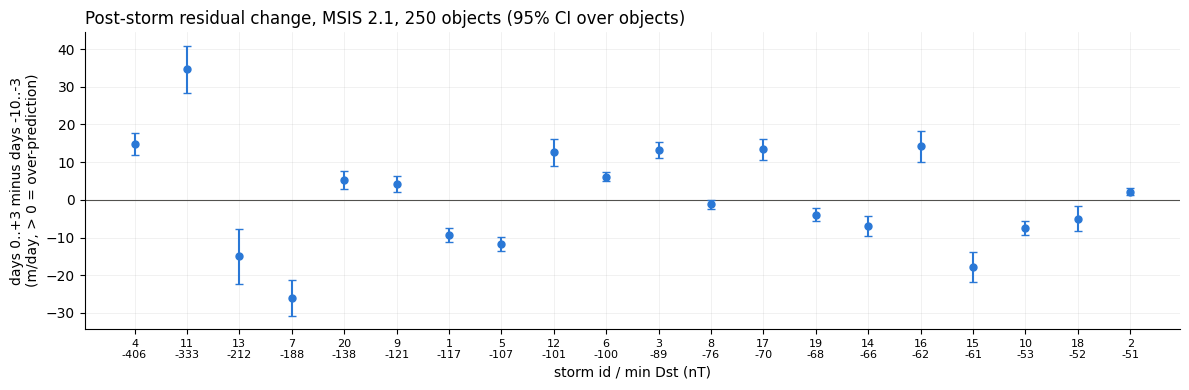

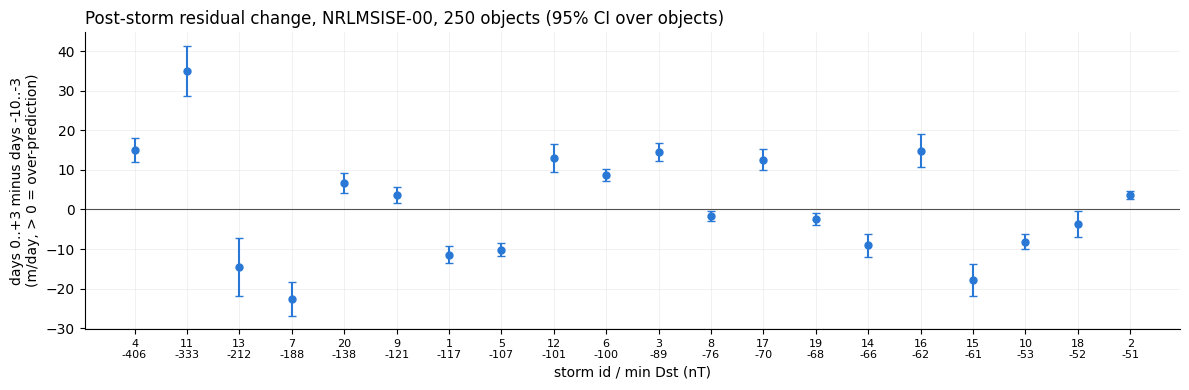

In [3]:
for col, key in (("MSIS 2.1", "msis21"), ("NRLMSISE-00", "nrlmsise00")):
    plot_storm_change_means(out["by_storm"], storms, col,
                            f"Post-storm residual change, {col}, {out['n_objects']} objects (95% CI over objects)",
                            out_path=RESULTS / f"extreme_storms_{key}.png")

## 2. TLE-blur check: smoothing and lag

The prediction is smoothed with a centred, time-weighted 1, 2, 3-day window (factor refitted
on the quiet fit intervals, ~1). If the days 0..+3 over-prediction were only TLE blur, it would
shrink to zero as the prediction is blurred like the TLEs.

In [4]:
key = out["by_storm"].reset_index()
key = key[key["storm_id"].isin(list(names))].assign(storm=lambda d: d["storm_id"].map(names))
key.pivot_table(index="outcome", columns="storm", values=["mean", "ci_lo", "ci_hi"], sort=False).round(1)

mean                                                  ci_lo                                                  ci_hi                                    
storm                 May 2024 (extreme) Oct 2024 (severe) Dec 2024 (severe) May 2024 (extreme) Oct 2024 (severe) Dec 2024 (severe) May 2024 (extreme) Oct 2024 (severe) Dec 2024 (severe)
outcome                                                                                                                                                                                   
MSIS 2.1                            14.8              34.6               -15               11.9              28.4             -22.3               17.7              40.9              -7.6
NRLMSISE-00                           15                35             -14.6               12.1              28.7             -21.9                 18              41.3              -7.3
MSIS 2.1 smoothed 1 d               14.4              34.4             -15.1               11.6              28.2             -22.5               17.2              40.6              -7.7
MSIS 2.1 smoothed 2 d               11.1              31.5             -15.7                8.5              25.6             -23.1               13.6              37.5              -8.3
MSIS 2.1 smoothed 3 d                6.9              28.4             -17.3                4.6              22.8             -24.7                9.2              33.9              -9.8

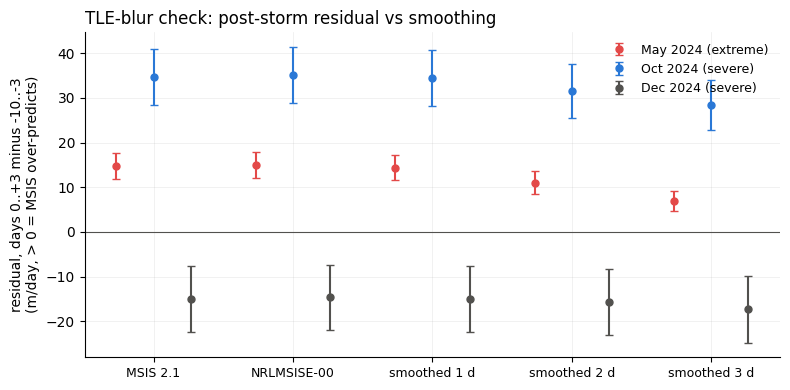

In [5]:
fig = plot_extreme_smoothing(out["by_storm"].loc[list(dict.fromkeys(out["by_storm"].index.get_level_values(0)))],
                             names, out_path=RESULTS / "extreme_smoothing.png")

,mean,se,objects
lag_h,,,
-24,0.638,0.0074,250
-21,0.65,0.0075,250
-18,0.661,0.0075,250
-15,0.671,0.0075,250
-12,0.68,0.0076,250
-9,0.689,0.0077,250
-6,0.695,0.0078,250
-3,0.697,0.0079,250
0,0.694,0.008,250


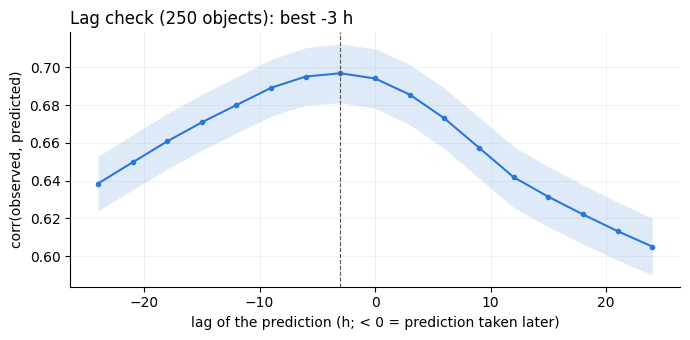

In [6]:
fig = plot_lag_check(out["lags"], out_path=RESULTS / "extreme_lag.png")
out["lags"].round(4)

## 3. Calm-to-calm loss

Per object and storm: `obs_m` = a(t1) - a(t0), `pred_m` = MSIS 2.1 over the same intervals,
`diff_m` = obs - pred (> 0: less loss than predicted, i.e. MSIS over-predicts),
`obs / pred` < 1 means the same. Two baselines make it comparable with the
baseline-relative residual: minus the object's own pre-storm error (days -10..-3, after the
previous storm) times the span, and minus its mean error on quiet intervals within +-30 days.
CIs: objects resampled within a storm (one or two storms), whole storms otherwise.
Storms without a calm day before or after (the dense March-April 2025 run) drop out.

In [7]:
spans = physics.calm_spans(storms, physics.calm_days(inputs[2]))
calm0 = out["calm"][0]
used = calm0.groupby("storm_id").agg(t0=("t0", "min"), t1=("t1", "max"), span_days=("span_days", "mean"),
                                       objects=("norad_id", "nunique"))
print(f"{calm0['storm_id'].nunique()} of {len(storms)} storms have a calm day before and after; "
      f"{len(calm0):,} storm-object pairs, coverage >= {calm0['coverage'].min():.3f}")
used.join(storms.set_index("storm_id")[["class", "min_dst"]])

13 of 20 storms have a calm day before and after; 3,244 storm-object pairs, coverage >= 1.000


,t0,t1,span_days,objects,class,min_dst
storm_id,,,,,,
1,2024-04-11 06:32:09.348296,2024-04-24 06:30:49.037768,8.69,250,strong,-117
3,2024-04-29 00:16:28.625094,2024-05-07 20:54:25.198275,5.48,250,moderate,-89
4,2024-05-04 07:39:54.862273,2024-05-22 06:02:39.215310,12.7,250,extreme,-406
5,2024-06-23 10:35:31.602345,2024-07-01 04:20:22.131760,5.69,250,strong,-107
6,2024-07-29 07:28:11.961117,2024-08-07 02:13:26.940275,7.58,250,moderate,-100
7,2024-08-07 11:32:14.103464,2024-08-15 22:48:02.304288,6.64,250,strong,-188
8,2024-08-24 00:56:29.323398,2024-09-03 08:50:26.727350,8.6,250,moderate,-76
9,2024-09-08 23:25:02.495706,2024-09-22 12:52:06.736531,11.6,249,strong,-121
10,2024-09-21 01:32:45.563133,2024-09-28 13:36:20.862428,5.85,245,moderate,-53


In [8]:
t = out["tables"][0]
cols = ["ratio", "ratio_lo", "ratio_hi", "diff_m", "diff_lo", "diff_hi", "diff_adj_m", "adj_lo", "adj_hi",
        "diff_quiet_m", "quiet_lo", "quiet_hi", "span_days", "n_storms", "n_objects", "ci_basis"]
print("By storm class:")
display(t["class"][cols].round(2))
print("Key storms:")
t["storm"].set_index("storm")[cols].round(2)

By storm class:


,ratio,ratio_lo,ratio_hi,diff_m,diff_lo,diff_hi,diff_adj_m,adj_lo,adj_hi,diff_quiet_m,quiet_lo,quiet_hi,span_days,n_storms,n_objects,ci_basis
class,,,,,,,,,,,,,,,,
moderate,0.9,0.75,1.03,41.8,1.61,82.9,11,-11.1,35.4,27.3,-0.7,57.4,7.26,5,250,storms
strong,1.02,0.98,1.08,-11.9,-27.1,7.41,-28,-80.9,15.6,-18.6,-45.1,9.89,7.92,5,250,storms
severe,1,0.98,1.02,1.27,-16.1,18.4,-2.76,-21,14.9,34.4,17.3,51.5,9.23,2,250,objects
extreme,0.91,0.9,0.92,71.5,60.6,82.6,-75.1,-92,-59.4,-1.03,-10.3,7.04,12.7,1,250,objects


Key storms:


,ratio,ratio_lo,ratio_hi,diff_m,diff_lo,diff_hi,diff_adj_m,adj_lo,adj_hi,diff_quiet_m,quiet_lo,quiet_hi,span_days,n_storms,n_objects,ci_basis
storm,,,,,,,,,,,,,,,,
May 2024 (extreme),0.91,0.9,0.92,71.5,60.6,82.6,-75.1,-92,-59.4,-1.03,-10.3,7.04,12.7,1,250,objects
Oct 2024 (severe),0.86,0.84,0.87,127,105,152,137,115,162,169,144,197,8.71,1,250,objects
Dec 2024 (severe),1.19,1.17,1.22,-125,-152,-100,-142,-172,-115,-101,-125,-78.6,9.75,1,250,objects


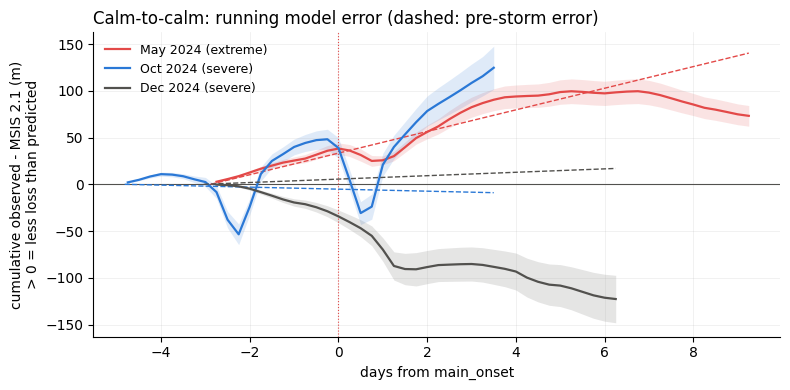

In [9]:
fig = plot_calm_cumulative(out["curves"], names, out_path=RESULTS / "extreme_cumulative.png")

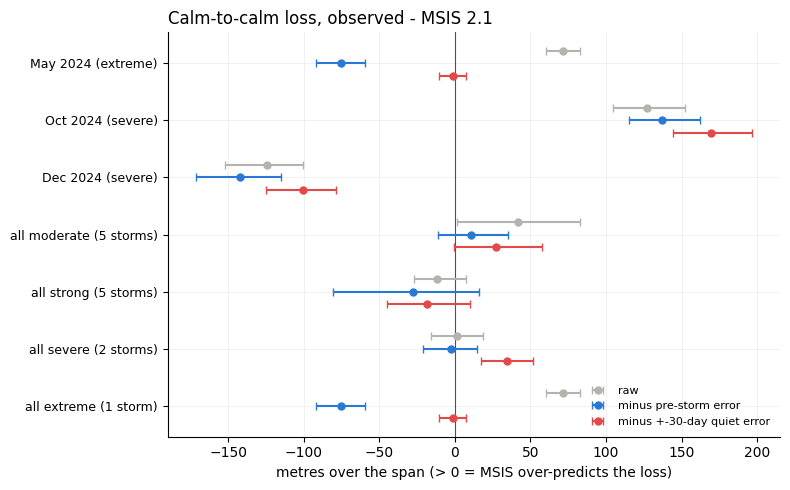

In [10]:
rows = pd.concat([t["storm"].set_index("storm"), t["class"].rename(index=lambda c: f"all {c}")])
fig = plot_calm_summary(rows, [f"{i} ({int(r.n_storms)} storm{'s' if r.n_storms > 1 else ''})" if i.startswith("all") else i
                               for i, r in rows.iterrows()],
                        out_path=RESULTS / "extreme_calm_to_calm.png")

Sensitivity: a TLE fitted on the first calm day still uses tracking from the days before,
so the calm day after is pushed 2 and 3 days later (in the simulator this makes the loss
blur-free for a 2-day blur, `tests/test_extreme_check.py`).

In [11]:
sens = pd.concat({f"+{e} d": out["tables"][e]["storm"].set_index("storm")[["ratio", "diff_m", "diff_adj_m", "adj_lo", "adj_hi",
                                                                            "diff_quiet_m", "quiet_lo", "quiet_hi", "span_days"]]
                  for e in ec.EXTRA_DAYS})
sens.round(2)

ratio  diff_m  diff_adj_m  adj_lo  adj_hi  diff_quiet_m  quiet_lo  quiet_hi  span_days
     storm                                                                                                     
+0 d May 2024 (extreme)   0.91    71.5       -75.1     -92   -59.4         -1.03     -10.3      7.04       12.7
     Oct 2024 (severe)    0.86     127         137     115     162           169       144       197       8.71
     Dec 2024 (severe)    1.19    -125        -142    -172    -115          -101      -125     -78.6       9.75
+2 d May 2024 (extreme)   0.91    75.2       -94.1    -114   -75.1          -8.4     -18.5      0.57       14.6
     Oct 2024 (severe)    0.86     140         152     126     181           191       162       223       10.7
     Dec 2024 (severe)    1.18    -131        -152    -185    -122          -102      -127       -79       11.7
+3 d May 2024 (extreme)   0.91    76.7        -104    -125   -83.5         -12.7     -23.3     -3.31       15.6
     Oct 2024 (severe)    0.87     143         156     129     187           199       169       232       11.7
     Dec 2024 (severe)    1.17    -141        -166    -203    -133          -108      -133     -83.8       13.8

Negative control: the 15 high-altitude objects (1,040-1,211 km) feel almost no storm drag,
so their calm-to-calm difference should be ~0.

In [12]:
out["high_summary"][["obs_m", "pred_m", "diff_m", "diff_lo", "diff_hi", "diff_quiet_m", "quiet_lo", "quiet_hi",
                     "n_storms", "n_objects"]].round(2)

,obs_m,pred_m,diff_m,diff_lo,diff_hi,diff_quiet_m,quiet_lo,quiet_hi,n_storms,n_objects
class,,,,,,,,,,
extreme,-46.4,-43.5,-2.88,-7.66,0.38,-7.08,-15.7,-0.99,1,15
moderate,-16.2,-17.8,1.57,-0.86,3.67,1.11,-0.94,2.54,5,15
severe,-32.4,-31.3,-1.12,-3.48,1.07,-1.21,-4.07,1.09,2,15
strong,-25.3,-24,-1.3,-2.85,0.16,-1.66,-3.38,0.02,5,15


## 4. By altitude band

Same calm-to-calm summary per altitude band (mean altitude over the span): all usable storms
together, and the key storms band by band.

In [13]:
print("All storms, by band:")
display(t["alt"][cols].round(2))
sa = t["storm_alt"].set_index(["storm", "alt_band"])
sa[["obs_m", "pred_m", "ratio", "ratio_lo", "ratio_hi", "diff_quiet_m", "quiet_lo", "quiet_hi", "diff_adj_m",
    "adj_lo", "adj_hi", "n_objects"]].round(2)

All storms, by band:


,ratio,ratio_lo,ratio_hi,diff_m,diff_lo,diff_hi,diff_adj_m,adj_lo,adj_hi,diff_quiet_m,quiet_lo,quiet_hi,span_days,n_storms,n_objects,ci_basis
alt_band,,,,,,,,,,,,,,,,
< 500 km,1,0.94,1.05,15.2,-22.2,55.6,-32.2,-73.9,9.92,3.81,-33,39.3,8.32,13,11,storms
500-600 km,0.99,0.92,1.05,20.5,-33.8,78.9,-29,-84.8,31.4,12.2,-41.2,63.4,8.35,13,36,storms
600-700 km,0.96,0.89,1.04,23.2,-12.1,58.4,-13.6,-50.5,25.1,11.9,-21.7,43.5,8.22,13,129,storms
>= 700 km,0.96,0.88,1.04,12.4,-7.79,31.7,-6.35,-27.5,13.9,5.81,-13.5,23.4,8.22,13,117,storms


obs_m    pred_m  ratio  ratio_lo  ratio_hi  diff_quiet_m  quiet_lo  quiet_hi  diff_adj_m  adj_lo  adj_hi  n_objects
storm              alt_band                                                                                                                          
May 2024 (extreme) < 500 km   -1.16e+03 -1.28e+03   0.91       0.9      0.92          5.21     -26.9      30.4        -140    -156    -129          4
                   500-600 km -1.09e+03 -1.23e+03   0.89      0.88       0.9          26.3      8.25      43.8        -110    -153   -72.8         18
                   600-700 km      -812      -896   0.91      0.89      0.92         -0.65     -15.8      11.7       -93.1    -121   -67.6        114
                   >= 700 km       -495      -542   0.91      0.89      0.94         -5.95     -20.1      6.92       -49.3   -73.6   -30.1        114
Oct 2024 (severe)  < 500 km   -1.26e+03  -1.4e+03    0.9      0.85      0.94           193       136       260         116    75.9     160          5
                   500-600 km -1.52e+03 -1.77e+03   0.86      0.85      0.88           325       238       428         212     160     270         22
                   600-700 km      -892 -1.04e+03   0.85      0.82      0.88           196       153       242         175     134     221        113
                   >= 700 km       -451      -528   0.85      0.83      0.87           111      85.3       137        83.6    62.9     107        110
Dec 2024 (severe)  < 500 km   -1.64e+03 -1.45e+03   1.14      1.11      1.15          -162      -293     -91.1        -204    -339    -125          8
                   500-600 km -1.88e+03 -1.65e+03   1.15      1.11      1.18          -180      -257      -105        -299    -395    -211         26
                   600-700 km      -824      -679   1.21      1.18      1.24          -119      -164     -83.3        -161    -215    -115        114
                   >= 700 km       -356      -289   1.24      1.19      1.27         -55.1     -78.3     -35.5       -76.7    -105   -52.2        102

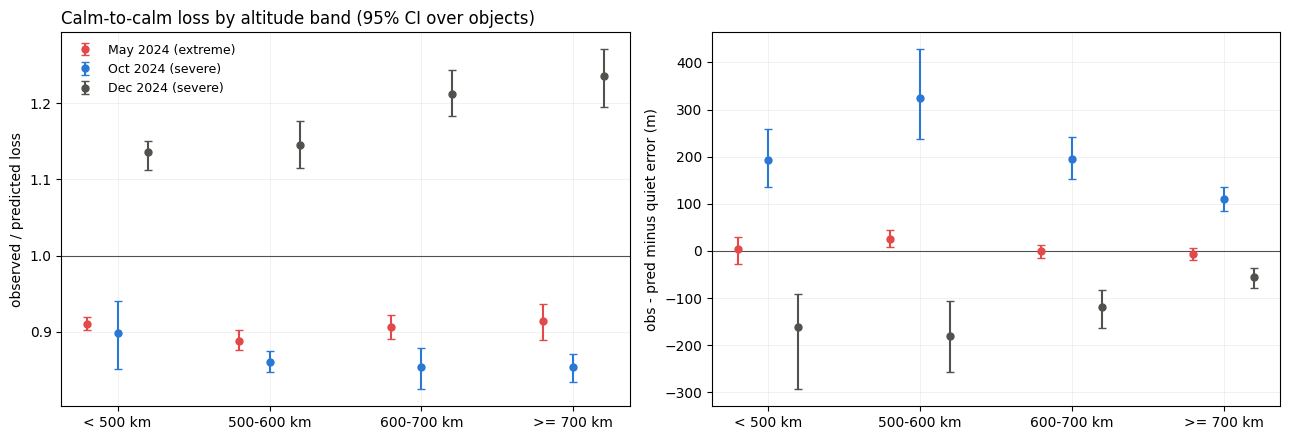

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
bands = list(ec.ALT_LABELS)
for ax, (col, lo, hi, label) in zip(axes, [("ratio", "ratio_lo", "ratio_hi", "observed / predicted loss"),
                                           ("diff_quiet_m", "quiet_lo", "quiet_hi", "obs - pred minus quiet error (m)")]):
    for j, (sid, name) in enumerate(names.items()):
        d = t["storm_alt"][t["storm_alt"]["storm_id"] == sid].set_index("alt_band").reindex(bands)
        x = np.arange(len(bands)) + (j - 1) * 0.2
        ax.errorbar(x, d[col], yerr=[d[col] - d[lo], d[hi] - d[col]], fmt="o", ms=5, capsize=3,
                    color=["#e34948", "#2a78d6", "#52514e"][j], label=name)
    ax.axhline(1 if col == "ratio" else 0, color="#52514e", lw=0.8)
    ax.set_xticks(range(len(bands)), bands)
    ax.set_ylabel(label)
    ax.grid(alpha=0.25, lw=0.5)
axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title("Calm-to-calm loss by altitude band (95% CI over objects)", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(RESULTS / "extreme_calm_by_alt.png", dpi=150)

## 5. Verdict (PLAN.md decision rules)

Per key storm (`physics.storm_check_label`): survives smoothing = the 3-day-smoothed days
0..+3 change has its 95% interval above 0; shows in calm-to-calm = the calm-to-calm
difference is above 0 under both baselines. Overall verdict over May and Oct 2024
(`physics.extreme_storm_verdict`).

In [15]:
for sid, label in out["labels"].items():
    print(f"{names[sid]:22s} {label}")
print()
print("Verdict:", out["verdict"])

May 2024 (extreme)     mixed: survives smoothing, not in calm-to-calm
Oct 2024 (severe)      real model overshoot
Dec 2024 (severe)      no over-prediction

Verdict: mixed (May 2024: survives smoothing, not in calm-to-calm; Oct 2024: real model overshoot)


## 6. Verdict

**Mixed: Oct 2024 is a real model overshoot; May 2024 is a timing error, not an overshoot of the total. Do not headline "models recover too slowly after storms".**

- **All 20 storms**: no post-storm over-prediction. MSIS 2.1 days 0..+3 change +0.8 m/day (95% CI -5.8 to 7.4; NRLMSISE-00 +1.3), -1.8 without May/Oct, -1.1 after 3-day smoothing. Best lag -3 h, correlation 0.697 vs 0.694 at 0 h: negligible.
- **TLE-blur check**: unlike the two rocket bodies of notebook 04, the May 2024 excess does not vanish with smoothing on 250 objects: +14.8 -> +6.9 m/day (3 days, CI 4.6 to 9.2). Oct 2024 +34.6 -> +28.4. Dec 2024 (the other severe storm) is negative throughout (-15.0 -> -17.3).
- **Calm-to-calm loss** (13 of 20 storms have a calm day before and after; coverage 100% with the onset gaps refilled):
  - Oct 2024: observed / predicted 0.86 (CI 0.84-0.87), +127 m raw, +137 m against the pre-storm error, +169 m against the +-30-day quiet error. Same with the calm day after pushed 2 or 3 days later (0.86, 0.87) and in every altitude band (0.85-0.90). Real overshoot.
  - May 2024: raw 0.91 (+71 m), but MSIS was already over-predicting before the storm (+11.6 m/day on days -7..-3, +5.7 m/day on quiet intervals within +-30 days). Against those baselines the total is not over-predicted: -75 m and -1 m (CI -10 to +7). The running error (cumulative plot) climbs at the pre-storm rate through day 4 and gives part back after day 6: MSIS puts the decay too early, not too much of it.
  - Dec 2024: observed / predicted 1.19, MSIS under-predicts the loss (-101 to -142 m), growing with altitude (1.14 below 500 km, 1.24 above 700 km).
- **Altitude**: no common altitude pattern across storms; the all-storm ratio is 0.96-1.00 in every band with CIs over 1.
- **Negative control**: high-altitude objects (1,040-1,211 km) differ by at most 7 m.
- **Simulator** (`tests/test_extreme_check.py`): a planted 40% density deficit is recovered to within 1 m per storm-object pair; with 2-day TLE blur, pushing the calm day after by 3 days recovers it within 5%.